# Aluno: Breno Alves

# Estudo de Caso MegaTelco - Preparação de Dados

## Disciplina: Inteligência Artificial e Aplicações - IIA007
## FATEC Ferraz de Vasconcelos
### Professora: Ana Rosa C. Tonão               
#### Data: 09/11/2026 

---------

## Descrição da Tarefa

**Segmentação de prováveis churners**

Parabéns! Você foi contratado pela AABC&D, uma prestigiada empresa de consultoria em análise.

Seu primeiro projeto será desenvolver e avaliar um modelo de previsão para a MegaTelco, uma empresa de telecomunicações.

Eles estão tendo um grande problema com a retenção de clientes no negócio de produtos e serviços sem fio, sendo que 20% dos clientes de telefonia celular abandonam o serviço quando seus contratos vencem.

Está ficando cada vez mais difícil adquirir novos clientes, pois o mercado de telefones celulares está saturado.

Churn (rotatividade) é a transferência de clientes de uma empresa para outra e é algo dispendioso em todos os sentidos: uma empresa precisa gastar em incentivos para atrair um cliente, enquanto outra empresa perde rendimento quando o cliente vai embora.

Você foi chamado para ajudar a entender o problema e encontrar uma solução.

Atrair novos clientes é muito mais caro do que manter os que já existem, por isso, uma boa verba de marketing foi alocada para evitar a rotatividade.

O objetivo da MegaTelco é identificar os prováveis *churners* para que possam direcioná-los com uma oferta muito atraente:

**Um período de carência de um ano com todas as comunicações pela metade do preço, sem compromisso.**

**Descrição dos dados**

Para este projeto, a MegaTelCo forneceu um conjunto de dados históricos de 14.088 clientes, a partir dos quais já criou dois conjuntos de dados: um conjunto de treino (dataset - churn_hw2_train.xlsx) com 9.856 clientes e um conjunto de teste (dataset - churn_hw2_test.xlsx) com 4.232 clientes.

No momento da coleta dos dados, cada cliente tinha permanecido na empresa ou tinha saído (churned).

Cada cliente é descrito pelas variáveis listadas abaixo:


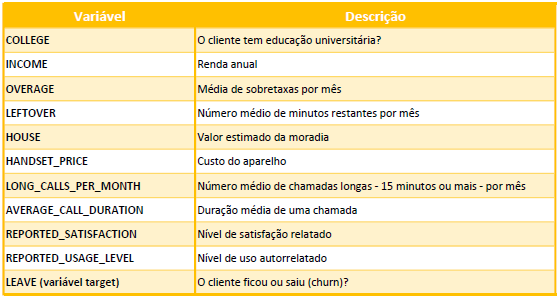

**Fonte**:

FAWCETT,T.;PROVOST,F. **Data Science para Negócios**.Rio de Janeiro, RJ:Alta Books, 2016.

----

## Importando as bibliotecas necessárias

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Pré-processamento
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [3]:
# Configurações visuais
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

### *Carregando os dados de TREINO*

In [6]:
retention_train = pd.read_excel('dataset - churn_hw2_train.xlsx')

### *Carregando os dados de TESTE*

In [7]:
retention_test = pd.read_excel('dataset - churn_hw2_test.xlsx')

-------
## (2) Inspecionando o conjunto de dados de TREINO
-------


In [8]:
# Visualizando os dados carregados - dataframe de TREINO
retention_train

,college,income,overage,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave
0,zero,109483,0,0,725532,767.0,1,2,avg,little,actively_looking_into_it,STAY
1,one,97561,62,63,220015,252.0,0,1,very_unsat,very_high,considering,STAY
2,zero,65489,67,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,STAY
3,zero,155377,0,8,471591,539.0,0,5,very_unsat,very_little,no,STAY
4,zero,84707,0,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,STAY
...,...,...,...,...,...,...,...,...,...,...,...,...
9851,zero,44872,0,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,LEAVE
9852,zero,107395,38,12,680632,519.0,4,4,very_unsat,little,considering,LEAVE
9853,zero,42242,0,47,779579,171.0,0,2,very_unsat,very_little,perhaps,LEAVE
9854,zero,36363,0,61,226787,199.0,1,1,unsat,high,no,LEAVE


In [9]:
print("Linhas, colunas: ",retention_train.shape, "\n")

print("Nomes de colunas: ",retention_train.columns, "\n")

print("Índices: ",retention_train.index, "\n")

Linhas, colunas:  (9856, 12) 

Nomes de colunas:  Index(['college', 'income', 'overage', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave'],
      dtype='str') 

Índices:  RangeIndex(start=0, stop=9856, step=1) 



-------
## (3) Inspecionando o conjunto de dados de TESTE
-------

In [10]:
# Visualizando os dados carregados - dataframe de TESTE
retention_test

,college,income,overage,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave
0,zero,133728,64,48,632969,626,3,2,unsat,high,no,STAY
1,one,50939,76,13,587207,336,3,5,avg,little,considering,STAY
2,one,36940,259,0,979303,236,10,8,very_sat,very_high,considering,STAY
3,zero,159902,0,20,213299,516,1,4,very_sat,high,actively_looking_into_it,STAY
4,one,52308,0,50,187864,394,27,2,very_unsat,little,considering,STAY
...,...,...,...,...,...,...,...,...,...,...,...,...
4227,zero,150781,92,0,438498,889,4,15,very_unsat,little,considering,LEAVE
4228,one,115273,165,6,478182,816,21,5,very_unsat,very_little,no,LEAVE
4229,one,27751,0,67,380831,158,0,2,unsat,very_high,actively_looking_into_it,LEAVE
4230,zero,20999,0,80,335638,237,1,2,unsat,little,actively_looking_into_it,LEAVE


In [11]:
print("Linhas, colunas: ",retention_test.shape, "\n")

print("Nomes de colunas: ",retention_test.columns, "\n")

print("Índices: ",retention_test.index, "\n")

Linhas, colunas:  (4232, 12) 

Nomes de colunas:  Index(['college', 'income', 'overage', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave'],
      dtype='str') 

Índices:  RangeIndex(start=0, stop=4232, step=1) 



-------
## (4) Preparando os dados de TREINO
-------

### *a) Verificando valores faltantes (Missing Values)*

In [12]:
retention_train.isna().sum()

college                        0
income                         0
overage                        0
leftover                       0
house                          0
handset_price                  3
over_15mins_calls_per_month    0
average_call_duration          0
reported_satisfaction          5
reported_usage_level           4
considering_change_of_plan     1
leave                          0
dtype: int64

### *b) Tratando os Missing Values de Variáveis Quantitativas*

In [13]:
# Coluna: handset_price
media_treino = retention_train['handset_price'].mean()
mediana_treino = retention_train['handset_price'].median()
moda_treino = retention_train['handset_price'].mode()

print(media_treino)
print(mediana_treino)
print(moda_treino)

402.7714401705064
321.0
0    148.0
Name: handset_price, dtype: float64


In [14]:
# Preenchendo com a mediana
retention_train['handset_price']= retention_train['handset_price'].fillna(mediana_treino)

### *c) Tratando os Missing Values de Variáveis Qualitativas*

Vamos usar a moda para preencher os valores das colunas:

* reported_satisfaction
* reported_usage_level           
* considering_change_of_plan  


In [15]:
moda_satisfaction = retention_train['reported_satisfaction'].mode()
moda_usage_level = retention_train['reported_usage_level'].mode()
moda_change_of_plan = retention_train['considering_change_of_plan'].mode()


print("Satisfação reportada (moda): ",moda_satisfaction, "\n")
print("Nível de uso reportado (moda): ",moda_usage_level, "\n")
print("Considerando trocar o plano? (moda): ",moda_change_of_plan, "\n")

Satisfação reportada (moda):  0    very_unsat
Name: reported_satisfaction, dtype: str 

Nível de uso reportado (moda):  0    little
Name: reported_usage_level, dtype: str 

Considerando trocar o plano? (moda):  0    considering
Name: considering_change_of_plan, dtype: str 



In [16]:
# Coluna: reported_satisfation
retention_train['reported_satisfaction'].fillna(retention_train['reported_satisfaction'].mode()[0], inplace=True)


/tmp/ipykernel_7081/76692555.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  retention_train['reported_satisfaction'].fillna(retention_train['reported_satisfaction'].mode()[0], inplace=True)


0              avg
1       very_unsat
2         very_sat
3       very_unsat
4       very_unsat
           ...    
9851      very_sat
9852    very_unsat
9853    very_unsat
9854         unsat
9855           sat
Name: reported_satisfaction, Length: 9856, dtype: str

In [17]:
# Coluna: reported_usage_level           
retention_train['reported_usage_level'].fillna(retention_train['reported_usage_level'].mode()[0], inplace=True)

/tmp/ipykernel_7081/53438031.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  retention_train['reported_usage_level'].fillna(retention_train['reported_usage_level'].mode()[0], inplace=True)


0            little
1         very_high
2         very_high
3       very_little
4         very_high
           ...     
9851         little
9852         little
9853    very_little
9854           high
9855      very_high
Name: reported_usage_level, Length: 9856, dtype: str

In [18]:
# Coluna: considering_change_of_plan                
retention_train['considering_change_of_plan'].fillna(retention_train['considering_change_of_plan'].mode()[0], inplace=True)

/tmp/ipykernel_7081/2785083139.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  retention_train['considering_change_of_plan'].fillna(retention_train['considering_change_of_plan'].mode()[0], inplace=True)


0       actively_looking_into_it
1                    considering
2       actively_looking_into_it
3                             no
4       actively_looking_into_it
                  ...           
9851    actively_looking_into_it
9852                 considering
9853                     perhaps
9854                          no
9855                 considering
Name: considering_change_of_plan, Length: 9856, dtype: str

In [19]:
retention_train.isna().sum()

college                        0
income                         0
overage                        0
leftover                       0
house                          0
handset_price                  0
over_15mins_calls_per_month    0
average_call_duration          0
reported_satisfaction          5
reported_usage_level           4
considering_change_of_plan     1
leave                          0
dtype: int64

### *d) Ordinal Encoding das Variáveis Categóricas ordinais*

Temos as seguintes variáveis categóricas ordinais no conjunto de dados:

* reported_satisfaction
* reported_usage_level
* considering_change_of_plan

*Tratando a variável ordinal (escala Likert de 5 níveis): **reported_satisfaction***

In [20]:
# Proporção de valores únicos em "reported_satisfaction"
prop_table = retention_train['reported_satisfaction'].value_counts(normalize=True)
print(prop_table)

reported_satisfaction
very_unsat    0.396813
very_sat      0.251447
unsat         0.199675
avg           0.098873
sat           0.053193
Name: proportion, dtype: float64


In [21]:
# Criando um mapeamento manual para a escala Likert
likert_map = {
    "very_unsat": 1,
    "unsat": 2,
    "avg": 3,
    "sat": 4,
    "very_sat": 5
}


In [22]:
# Aplicando o mapeamento
retention_train["reported_satisfaction_num"] = retention_train["reported_satisfaction"].map(likert_map)


In [23]:
print("\nReported Satisfaction Original: \n", retention_train['reported_satisfaction'],"\n\n")
print("\nCom escala Likert codificada: \n", retention_train['reported_satisfaction_num'],"\n\n")


Reported Satisfaction Original: 
 0              avg
1       very_unsat
2         very_sat
3       very_unsat
4       very_unsat
           ...    
9851      very_sat
9852    very_unsat
9853    very_unsat
9854         unsat
9855           sat
Name: reported_satisfaction, Length: 9856, dtype: str 



Com escala Likert codificada: 
 0       3.0
1       1.0
2       5.0
3       1.0
4       1.0
       ... 
9851    5.0
9852    1.0
9853    1.0
9854    2.0
9855    4.0
Name: reported_satisfaction_num, Length: 9856, dtype: float64 




*Tratando a variável ordinal (escala Likert de 5 níveis): **reported_usage_level***

In [24]:
# Proporção de valores únicos em "reported_usage_level"
prop_table = retention_train['reported_usage_level'].value_counts(normalize=True)
print(prop_table)

reported_usage_level
little         0.389870
very_high      0.253654
very_little    0.205136
high           0.103228
avg            0.048112
Name: proportion, dtype: float64


In [25]:
# Criando um mapeamento manual para a escala Likert
likert_map = {
    "very_little": 1,
    "little": 2,
    "avg": 3,
    "high": 4,
    "very_high": 5
}

In [26]:
# Aplicando o mapeamento
retention_train["reported_usage_level_num"] = retention_train["reported_usage_level"].map(likert_map)

In [27]:
print("\nReported Usage Level Original: \n", retention_train['reported_usage_level'],"\n\n")
print("\nCom escala Likert codificada: \n", retention_train['reported_usage_level_num'],"\n\n")


Reported Usage Level Original: 
 0            little
1         very_high
2         very_high
3       very_little
4         very_high
           ...     
9851            NaN
9852         little
9853    very_little
9854           high
9855      very_high
Name: reported_usage_level, Length: 9856, dtype: str 



Com escala Likert codificada: 
 0       2.0
1       5.0
2       5.0
3       1.0
4       5.0
       ... 
9851    NaN
9852    2.0
9853    1.0
9854    4.0
9855    5.0
Name: reported_usage_level_num, Length: 9856, dtype: float64 




*Tratando a variável ordinal (escala Likert de 5 níveis): **considering_change_of_plan***

In [28]:
# Proporção de valores únicos em "considering_change_of_plan"
prop_table = retention_train['considering_change_of_plan'].value_counts(normalize=True)
print(prop_table)   

considering_change_of_plan
considering                 0.398782
actively_looking_into_it    0.246778
no                          0.199797
never_thought               0.102689
perhaps                     0.051953
Name: proportion, dtype: float64


In [29]:
# Criando um mapeamento manual para a escala Likert
likert_map = {
    "never_thought": 1,
    "no": 2,
    "perhaps": 3,
    "considering": 4,
    "actively_looking_into_it": 5
}

In [31]:
# Aplicando o mapeamento
retention_train["considering_change_of_plan_num"] = retention_train["considering_change_of_plan"].map(likert_map)

In [32]:
print("\nConsiderando a troca de plano Original: \n", retention_train['considering_change_of_plan'],"\n\n")
print("\nCom escala Likert codificada: \n", retention_train['considering_change_of_plan_num'],"\n\n")


Considerando a troca de plano Original: 
 0       actively_looking_into_it
1                    considering
2       actively_looking_into_it
3                             no
4       actively_looking_into_it
                  ...           
9851    actively_looking_into_it
9852                 considering
9853                     perhaps
9854                          no
9855                 considering
Name: considering_change_of_plan, Length: 9856, dtype: str 



Com escala Likert codificada: 
 0       5.0
1       4.0
2       5.0
3       2.0
4       5.0
       ... 
9851    5.0
9852    4.0
9853    3.0
9854    2.0
9855    4.0
Name: considering_change_of_plan_num, Length: 9856, dtype: float64 




### *e) Label Encoding das Variáveis Categóricas sem ordem clara*

Temos somente uma feature sem ordem clara no conjunto de dados: **college**.

In [ ]:
# Proporção de valores únicos em "college"
prop_table = retention_train['college'].value_counts(normalize=True)
print(prop_table)   

college
zero    0.501116
one     0.498884
Name: proportion, dtype: float64


*Tratando a feature categórica que indica se o cliente tem nível superior (one) ou não (zero): **college***

In [34]:
# Criando um dicionário para o mapeamento desejado
label_map = {
    'zero': 0,
    'one': 1
}

In [35]:
# Aplicando o mapeamento à sua coluna usando o método .map() do pandas
retention_train['college'] = retention_train['college'].map(label_map)

In [36]:
retention_train

,college,income,overage,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,109483,0,0,725532,767.0,1,2,avg,little,actively_looking_into_it,STAY,3.0,2.0,5.0
1,1,97561,62,63,220015,252.0,0,1,very_unsat,very_high,considering,STAY,1.0,5.0,4.0
2,0,65489,67,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,STAY,5.0,5.0,5.0
3,0,155377,0,8,471591,539.0,0,5,very_unsat,very_little,no,STAY,1.0,1.0,2.0
4,0,84707,0,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,STAY,1.0,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,LEAVE,5.0,NaN,5.0
9852,0,107395,38,12,680632,519.0,4,4,very_unsat,little,considering,LEAVE,1.0,2.0,4.0
9853,0,42242,0,47,779579,171.0,0,2,very_unsat,very_little,perhaps,LEAVE,1.0,1.0,3.0
9854,0,36363,0,61,226787,199.0,1,1,unsat,high,no,LEAVE,2.0,4.0,2.0


### *f) Label Encoding da Variável Target*

* A variável alvo (target) deve ser numérica. 
* Se for categórica, use Label Encoding (para transformar em uma única coluna 0/1).

*Criando a nova variável target codificada: **leave_encoded***

In [37]:
# Criando o codificador
label_encoder = LabelEncoder()

In [38]:
# Ajustando/transformando a coluna alvo (target)
retention_train['leave_encoded'] = label_encoder.fit_transform(retention_train['leave'])

In [39]:
print(label_encoder.classes_)

['LEAVE' 'STAY']


In [40]:
retention_train

,college,income,overage,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num,leave_encoded
0,0,109483,0,0,725532,767.0,1,2,avg,little,actively_looking_into_it,STAY,3.0,2.0,5.0,1
1,1,97561,62,63,220015,252.0,0,1,very_unsat,very_high,considering,STAY,1.0,5.0,4.0,1
2,0,65489,67,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,STAY,5.0,5.0,5.0,1
3,0,155377,0,8,471591,539.0,0,5,very_unsat,very_little,no,STAY,1.0,1.0,2.0,1
4,0,84707,0,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,STAY,1.0,5.0,5.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,LEAVE,5.0,NaN,5.0,0
9852,0,107395,38,12,680632,519.0,4,4,very_unsat,little,considering,LEAVE,1.0,2.0,4.0,0
9853,0,42242,0,47,779579,171.0,0,2,very_unsat,very_little,perhaps,LEAVE,1.0,1.0,3.0,0
9854,0,36363,0,61,226787,199.0,1,1,unsat,high,no,LEAVE,2.0,4.0,2.0,0


-----

No nosso caso, ***o LabelEncoder do Sklearn não gerou a transformação mais adequada!***

Isso aconteceu porque este recurso "seta" o primeiro valor encontrado como 1, e depois trata de forma diferente os demais.

Vamos ter que "forçar" o label encoding que precisamos:

* STAY  = 0
* LEAVE =  1

Vamos usar um recurso do próprio Pandas para isso.

-----

*Transformando diretamente a variável target: **leave***

In [41]:
# Criando um dicionário para o mapeamento desejado
label_map = {
    'STAY': 0,
    'LEAVE': 1
}

In [42]:
# Aplicando o mapeamento à sua coluna usando o método .map() do pandas
retention_train['leave'] = retention_train['leave'].map(label_map)

In [47]:
# Verifique como ficou diferente da nova variável leave_encoding que criamos anteriormente:
retention_train

,college,income,overage,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,109483,0,0,725532,767.0,1,2,avg,little,actively_looking_into_it,0,3.0,2.0,5.0
1,1,97561,62,63,220015,252.0,0,1,very_unsat,very_high,considering,0,1.0,5.0,4.0
2,0,65489,67,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0
3,0,155377,0,8,471591,539.0,0,5,very_unsat,very_little,no,0,1.0,1.0,2.0
4,0,84707,0,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0
9852,0,107395,38,12,680632,519.0,4,4,very_unsat,little,considering,1,1.0,2.0,4.0
9853,0,42242,0,47,779579,171.0,0,2,very_unsat,very_little,perhaps,1,1.0,1.0,3.0
9854,0,36363,0,61,226787,199.0,1,1,unsat,high,no,1,2.0,4.0,2.0


In [46]:
# Agora podemos "dropar" a variável criada anteriormente
retention_train = retention_train.drop(
    columns=[
        "leave_encoded"
    ]
)

KeyError: "['leave_encoded'] not found in axis"

In [49]:
retention_train

,college,income,overage,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,109483,0,0,725532,767.0,1,2,avg,little,actively_looking_into_it,0,3.0,2.0,5.0
1,1,97561,62,63,220015,252.0,0,1,very_unsat,very_high,considering,0,1.0,5.0,4.0
2,0,65489,67,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0
3,0,155377,0,8,471591,539.0,0,5,very_unsat,very_little,no,0,1.0,1.0,2.0
4,0,84707,0,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0
9852,0,107395,38,12,680632,519.0,4,4,very_unsat,little,considering,1,1.0,2.0,4.0
9853,0,42242,0,47,779579,171.0,0,2,very_unsat,very_little,perhaps,1,1.0,1.0,3.0
9854,0,36363,0,61,226787,199.0,1,1,unsat,high,no,1,2.0,4.0,2.0


### *g) Avaliando o balanceamento da amostra*

* Introduzir o conceito de classes desbalanceadas. 
* Se a proporção for muito desigual (ex: 90/10), a acurácia pode ser uma métrica enganosa.

leave
0    0.719765
1    0.280235
Name: proportion, dtype: float64


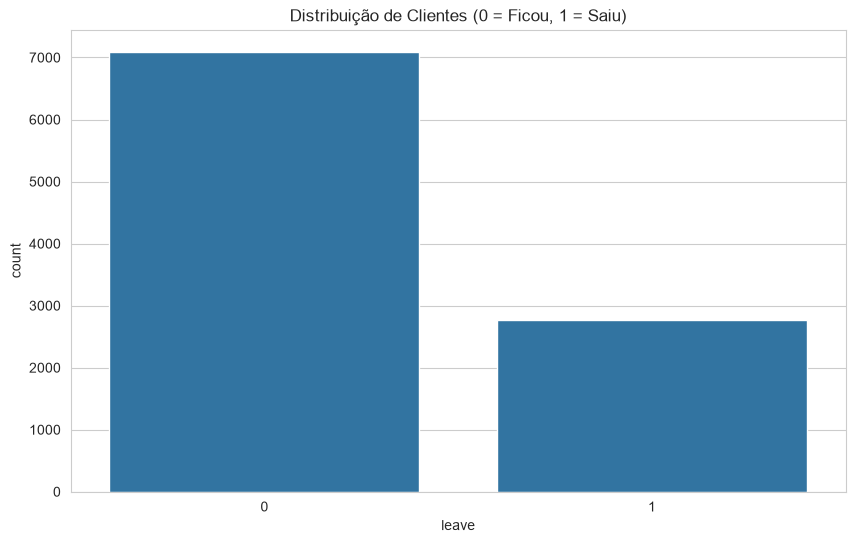

In [50]:
print(retention_train['leave'].value_counts(normalize=True))
sns.countplot(x='leave', data=retention_train)
plt.title('Distribuição de Clientes (0 = Ficou, 1 = Saiu)')
plt.show()

### *h) Analisando a correlação entre as variáveis quantitativas*

* Um mapa de calor ajuda a identificar quais features estão mais relacionadas com o churn e se há alta correlação entre elas (multicolinearidade).
* Observe os pares de features com correlação acima de 0.75 ou abaixo de -0.75, você tem um forte indício de multicolinearidade!

In [51]:
retention_train.dtypes

college                             int64
income                              int64
overage                             int64
leftover                            int64
house                               int64
handset_price                     float64
over_15mins_calls_per_month         int64
average_call_duration               int64
reported_satisfaction                 str
reported_usage_level                  str
considering_change_of_plan            str
leave                               int64
reported_satisfaction_num         float64
reported_usage_level_num          float64
considering_change_of_plan_num    float64
dtype: object

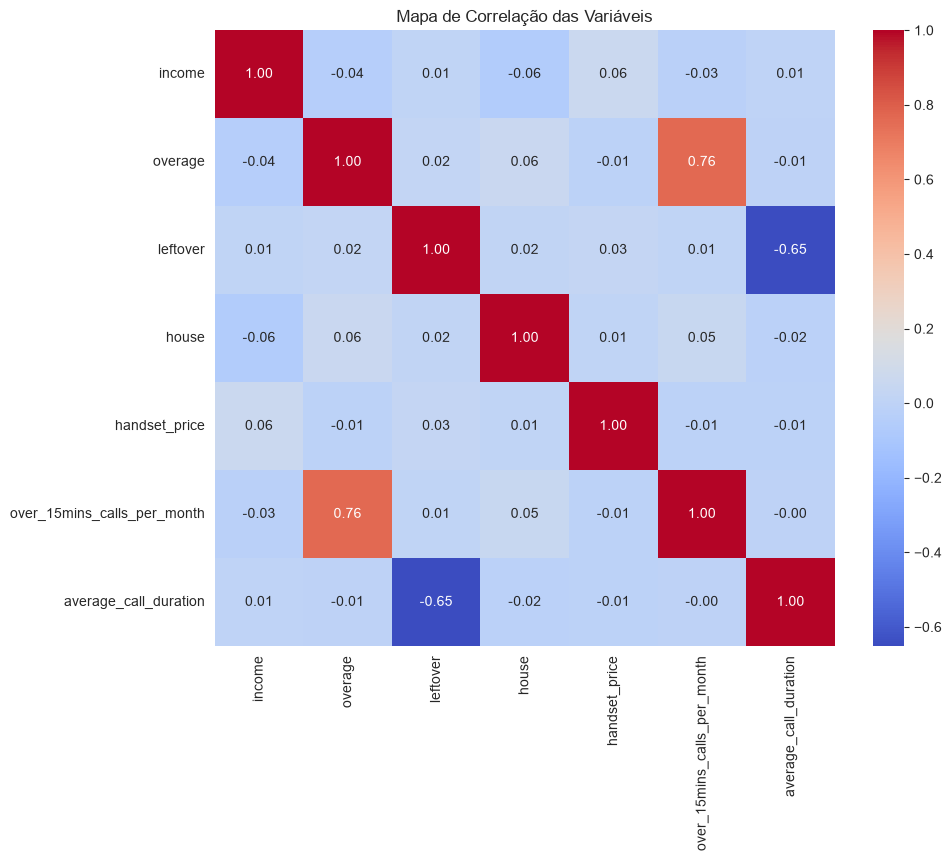

In [52]:
plt.figure(figsize=(10, 8))
corr_matrix = retention_train[['income', 'overage', 'leftover', 'house', 'handset_price', 
                               'over_15mins_calls_per_month','average_call_duration']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Mapa de Correlação das Variáveis')
plt.show()

-----
Podemos observar indícios de multicolinearidade entre os seguintes pares de features:

* 0,76 (correlação positiva): 
    * **overage** (média de sobretaxas por mês) e **over_15mins_calls_per_month** (número médio de chamadas longas - 15 minutos ou mais - por mês).

* -0,65 (correlação negativa): 
    * **leftover** (número médio de minutos restantes por mês) e **average_call_duration** (duração média de uma chamada).

### Vamos remover uma das features com alta correlação positiva e manter aquelas com correlação negativa (ainda estão abaixo de -0,75).    
-----

In [53]:
# Removendo a feature overage
retention_train = retention_train.drop(
    columns=[
        "overage"
    ]
)

In [54]:
retention_train

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,109483,0,725532,767.0,1,2,avg,little,actively_looking_into_it,0,3.0,2.0,5.0
1,1,97561,63,220015,252.0,0,1,very_unsat,very_high,considering,0,1.0,5.0,4.0
2,0,65489,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0
3,0,155377,8,471591,539.0,0,5,very_unsat,very_little,no,0,1.0,1.0,2.0
4,0,84707,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0
9852,0,107395,12,680632,519.0,4,4,very_unsat,little,considering,1,1.0,2.0,4.0
9853,0,42242,47,779579,171.0,0,2,very_unsat,very_little,perhaps,1,1.0,1.0,3.0
9854,0,36363,61,226787,199.0,1,1,unsat,high,no,1,2.0,4.0,2.0


### *i) Tratando observações duplicadas*

In [55]:
retention_train = retention_train.drop_duplicates()

### *Inspeção final do dataframe de TREINO*



In [56]:
print("Linhas, colunas: ",retention_train.shape, "\n")

print("Nomes de colunas: ",retention_train.columns, "\n")

print("Índices: ",retention_train.index, "\n")

Linhas, colunas:  (9854, 14) 

Nomes de colunas:  Index(['college', 'income', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave', 'reported_satisfaction_num',
       'reported_usage_level_num', 'considering_change_of_plan_num'],
      dtype='str') 

Índices:  Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       9846, 9847, 9848, 9849, 9850, 9851, 9852, 9853, 9854, 9855],
      dtype='int64', length=9854) 



-------
## (5) Preparando os dados de TESTE
-------

### *a) Verificando valores faltantes (Missing Values)*


In [57]:
retention_test.isna().sum()

college                        0
income                         0
overage                        0
leftover                       0
house                          0
handset_price                  0
over_15mins_calls_per_month    0
average_call_duration          0
reported_satisfaction          0
reported_usage_level           0
considering_change_of_plan     0
leave                          0
dtype: int64

### *b) Tratando os Missing Values*

Não há missing values no conjunto de dados de Teste.

### *c) Ordinal Encoding das Variáveis Categóricas ordinais*

Temos as seguintes variáveis categóricas ordinais no conjunto de dados:

* reported_satisfaction
* reported_usage_level
* considering_change_of_plan


*Tratando a variável ordinal (escala Likert de 5 níveis): **reported_satisfaction***


In [58]:
# Proporção de valores únicos em "reported_satisfaction"
prop_table = retention_test['reported_satisfaction'].value_counts(normalize=True)
print(prop_table)

reported_satisfaction
very_unsat    0.387760
very_sat      0.254490
unsat         0.199433
avg           0.107750
sat           0.050567
Name: proportion, dtype: float64


In [59]:
# Criando um mapeamento manual para a escala Likert
likert_map = {
    "very_unsat": 1,
    "unsat": 2,
    "avg": 3,
    "sat": 4,
    "very_sat": 5
}

In [60]:
# Aplicando o mapeamento
retention_test["reported_satisfaction_num"] = retention_test["reported_satisfaction"].map(likert_map)

In [61]:
print("\nReported Satisfaction Original: \n", retention_test['reported_satisfaction'],"\n\n")
print("\nCom escala Likert codificada: \n", retention_test['reported_satisfaction_num'],"\n\n")


Reported Satisfaction Original: 
 0            unsat
1              avg
2         very_sat
3         very_sat
4       very_unsat
           ...    
4227    very_unsat
4228    very_unsat
4229         unsat
4230         unsat
4231    very_unsat
Name: reported_satisfaction, Length: 4232, dtype: str 



Com escala Likert codificada: 
 0       2
1       3
2       5
3       5
4       1
       ..
4227    1
4228    1
4229    2
4230    2
4231    1
Name: reported_satisfaction_num, Length: 4232, dtype: int64 




*Tratando a variável ordinal (escala Likert de 5 níveis): **reported_usage_level***

In [62]:
# Proporção de valores únicos em "reported_usage_level"
prop_table = retention_test['reported_usage_level'].value_counts(normalize=True)
print(prop_table)

reported_usage_level
little         0.398393
very_high      0.256616
very_little    0.195888
high           0.095936
avg            0.053166
Name: proportion, dtype: float64


In [63]:
# Criando um mapeamento manual para a escala Likert
likert_map = {
    "very_little": 1,
    "little": 2,
    "avg": 3,
    "high": 4,
    "very_high": 5
}

In [64]:
# Aplicando o mapeamento
retention_test["reported_usage_level_num"] = retention_test["reported_usage_level"].map(likert_map)

In [65]:
print("\nReported Usage Level Original: \n", retention_test['reported_usage_level'],"\n\n")
print("\nCom escala Likert codificada: \n", retention_test['reported_usage_level_num'],"\n\n")


Reported Usage Level Original: 
 0              high
1            little
2         very_high
3              high
4            little
           ...     
4227         little
4228    very_little
4229      very_high
4230         little
4231            avg
Name: reported_usage_level, Length: 4232, dtype: str 



Com escala Likert codificada: 
 0       4
1       2
2       5
3       4
4       2
       ..
4227    2
4228    1
4229    5
4230    2
4231    3
Name: reported_usage_level_num, Length: 4232, dtype: int64 




*Tratando a variável ordinal (escala Likert de 5 níveis): **considering_change_of_plan***

In [66]:
# Proporção de valores únicos em "considering_change_of_plan"
prop_table = retention_test['considering_change_of_plan'].value_counts(normalize=True)
print(prop_table)

considering_change_of_plan
considering                 0.396267
actively_looking_into_it    0.252127
no                          0.203214
never_thought               0.094991
perhaps                     0.053403
Name: proportion, dtype: float64


In [67]:
# Criando um mapeamento manual para a escala Likert
likert_map = {
    "never_thought": 1,
    "no": 2,
    "perhaps": 3,
    "considering": 4,
    "actively_looking_into_it": 5
}

In [68]:
# Aplicando o mapeamento
retention_test["considering_change_of_plan_num"] = retention_test["considering_change_of_plan"].map(likert_map)

In [69]:
print("\nConsiderando a troca de plano Original: \n", retention_test['considering_change_of_plan'],"\n\n")
print("\nCom escala Likert codificada: \n", retention_test['considering_change_of_plan_num'],"\n\n")


Considerando a troca de plano Original: 
 0                             no
1                    considering
2                    considering
3       actively_looking_into_it
4                    considering
                  ...           
4227                 considering
4228                          no
4229    actively_looking_into_it
4230    actively_looking_into_it
4231    actively_looking_into_it
Name: considering_change_of_plan, Length: 4232, dtype: str 



Com escala Likert codificada: 
 0       2
1       4
2       4
3       5
4       4
       ..
4227    4
4228    2
4229    5
4230    5
4231    5
Name: considering_change_of_plan_num, Length: 4232, dtype: int64 




### *d) Label Encoding das Variáveis Categóricas sem ordem clara*

Temos somente uma feature sem ordem clara no conjunto de dados: **college**.


In [70]:
# Proporção de valores únicos em "college"
prop_table = retention_test['college'].value_counts(normalize=True)
print(prop_table)

college
zero    0.50189
one     0.49811
Name: proportion, dtype: float64



*Tratando a feature categórica que indica se o cliente tem nível superior (one) ou não (zero): **college***

In [71]:
# Criando um dicionário para o mapeamento desejado
label_map = {
    'zero': 0,
    'one': 1
}

In [72]:
# Aplicando o mapeamento à sua coluna usando o método .map() do pandas
retention_test['college'] = retention_test['college'].map(label_map)

In [73]:
retention_test

,college,income,overage,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,133728,64,48,632969,626,3,2,unsat,high,no,STAY,2,4,2
1,1,50939,76,13,587207,336,3,5,avg,little,considering,STAY,3,2,4
2,1,36940,259,0,979303,236,10,8,very_sat,very_high,considering,STAY,5,5,4
3,0,159902,0,20,213299,516,1,4,very_sat,high,actively_looking_into_it,STAY,5,4,5
4,1,52308,0,50,187864,394,27,2,very_unsat,little,considering,STAY,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4227,0,150781,92,0,438498,889,4,15,very_unsat,little,considering,LEAVE,1,2,4
4228,1,115273,165,6,478182,816,21,5,very_unsat,very_little,no,LEAVE,1,1,2
4229,1,27751,0,67,380831,158,0,2,unsat,very_high,actively_looking_into_it,LEAVE,2,5,5
4230,0,20999,0,80,335638,237,1,2,unsat,little,actively_looking_into_it,LEAVE,2,2,5


### *e) Label Encoding da Variável Target*

* A variável alvo (target) deve ser numérica. 
* Se for categórica, use Label Encoding (para transformar em uma única coluna 0/1).

*Transformando diretamente a variável target: **leave***

In [74]:
# Criando um dicionário para o mapeamento desejado
label_map = {
    'STAY': 0,
    'LEAVE': 1
}

In [75]:
# Aplicando o mapeamento à sua coluna usando o método .map() do pandas
retention_test['leave'] = retention_test['leave'].map(label_map)

In [76]:
retention_test

,college,income,overage,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,133728,64,48,632969,626,3,2,unsat,high,no,0,2,4,2
1,1,50939,76,13,587207,336,3,5,avg,little,considering,0,3,2,4
2,1,36940,259,0,979303,236,10,8,very_sat,very_high,considering,0,5,5,4
3,0,159902,0,20,213299,516,1,4,very_sat,high,actively_looking_into_it,0,5,4,5
4,1,52308,0,50,187864,394,27,2,very_unsat,little,considering,0,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4227,0,150781,92,0,438498,889,4,15,very_unsat,little,considering,1,1,2,4
4228,1,115273,165,6,478182,816,21,5,very_unsat,very_little,no,1,1,1,2
4229,1,27751,0,67,380831,158,0,2,unsat,very_high,actively_looking_into_it,1,2,5,5
4230,0,20999,0,80,335638,237,1,2,unsat,little,actively_looking_into_it,1,2,2,5


### *f) Avaliando o balanceamento da amostra*

* Introduzir o conceito de classes desbalanceadas. 
* Se a proporção for muito desigual (ex: 90/10), a acurácia pode ser uma métrica enganosa.


leave
0    0.721645
1    0.278355
Name: proportion, dtype: float64


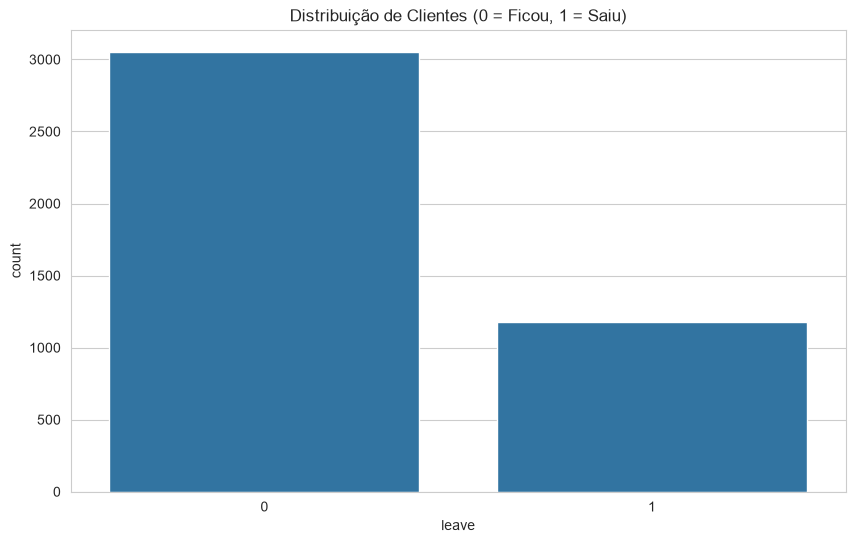

In [77]:
print(retention_test['leave'].value_counts(normalize=True))
sns.countplot(x='leave', data=retention_test)
plt.title('Distribuição de Clientes (0 = Ficou, 1 = Saiu)')
plt.show()

### *g) Analisando a correlação entre as variáveis quantitativas*

* Um mapa de calor ajuda a identificar quais features estão mais relacionadas com o churn e se há alta correlação entre elas (multicolinearidade).
* Observe os pares de features com correlação acima de 0.75 ou abaixo de -0.75, você tem um forte indício de multicolinearidade!


In [78]:
retention_test.dtypes

college                           int64
income                            int64
overage                           int64
leftover                          int64
house                             int64
handset_price                     int64
over_15mins_calls_per_month       int64
average_call_duration             int64
reported_satisfaction               str
reported_usage_level                str
considering_change_of_plan          str
leave                             int64
reported_satisfaction_num         int64
reported_usage_level_num          int64
considering_change_of_plan_num    int64
dtype: object

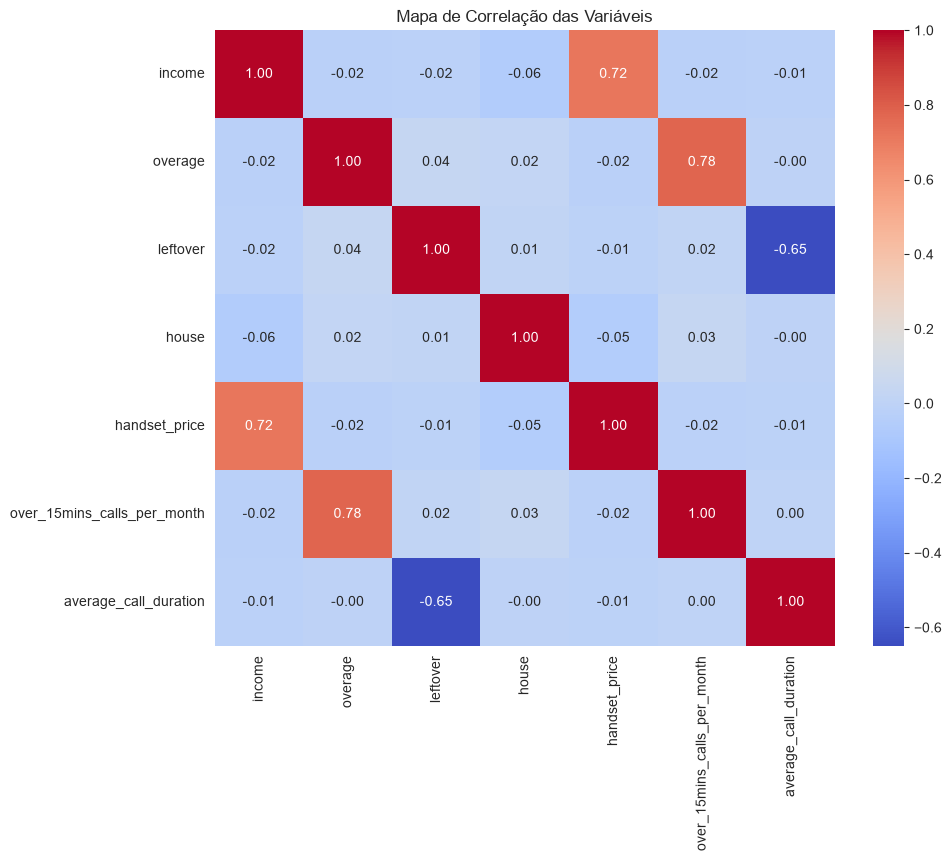

In [79]:
plt.figure(figsize=(10, 8))
corr_matrix = retention_test[['income', 'overage', 'leftover', 'house', 'handset_price', 
                               'over_15mins_calls_per_month','average_call_duration']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Mapa de Correlação das Variáveis')
plt.show()

-----
Podemos observar indícios de multicolinearidade entre os seguintes pares de features:

* 0,76 (correlação positiva): 
    * **overage** (média de sobretaxas por mês) e **over_15mins_calls_per_month** (número médio de chamadas longas - 15 minutos ou mais - por mês).

* 0,72 (correlação positiva): 
    * **income** (renda mensal) e **handset_price** (preço do smartphone).

* -0,65 (correlação negativa): 
    * **leftover** (número médio de minutos restantes por mês) e **average_call_duration** (duração média de uma chamada).

### Vamos remover uma das features com alta correlação positiva e manter as outras duas (pois a correlação absoluta ainda está abaixo de 0,75).   
-----


In [80]:
# Removendo a feature overage
retention_test = retention_test.drop(
    columns=[
        "overage"
    ]
)

In [81]:
retention_test

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,133728,48,632969,626,3,2,unsat,high,no,0,2,4,2
1,1,50939,13,587207,336,3,5,avg,little,considering,0,3,2,4
2,1,36940,0,979303,236,10,8,very_sat,very_high,considering,0,5,5,4
3,0,159902,20,213299,516,1,4,very_sat,high,actively_looking_into_it,0,5,4,5
4,1,52308,50,187864,394,27,2,very_unsat,little,considering,0,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4227,0,150781,0,438498,889,4,15,very_unsat,little,considering,1,1,2,4
4228,1,115273,6,478182,816,21,5,very_unsat,very_little,no,1,1,1,2
4229,1,27751,67,380831,158,0,2,unsat,very_high,actively_looking_into_it,1,2,5,5
4230,0,20999,80,335638,237,1,2,unsat,little,actively_looking_into_it,1,2,2,5


### *i) Tratando observações duplicadas*

In [82]:
retention_test = retention_test.drop_duplicates()

### *e) Inspecionando o dataframe de TESTE*

In [83]:
print("Linhas, colunas: ",retention_test.shape, "\n")

print("Nomes de colunas: ",retention_test.columns, "\n")

print("Índices: ",retention_test.index, "\n")

Linhas, colunas:  (4230, 14) 

Nomes de colunas:  Index(['college', 'income', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave', 'reported_satisfaction_num',
       'reported_usage_level_num', 'considering_change_of_plan_num'],
      dtype='str') 

Índices:  Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       4222, 4223, 4224, 4225, 4226, 4227, 4228, 4229, 4230, 4231],
      dtype='int64', length=4230) 



-------
## (6) Identificando Outliers
-------

In [84]:
# Função para comparar uma coluna específica
def comparar_boxplot(coluna):
    dados = pd.DataFrame({
        "Treino": retention_train[coluna],
        "Teste": retention_test[coluna]
    })
    dados_melt = dados.melt(var_name="Dataset", value_name=coluna)

    plt.figure(figsize=(8,5))
    sns.boxplot(x="Dataset", y=coluna, data=dados_melt)
    plt.title(f"Boxplot de {coluna} (Treino vs Teste)")
    plt.show()

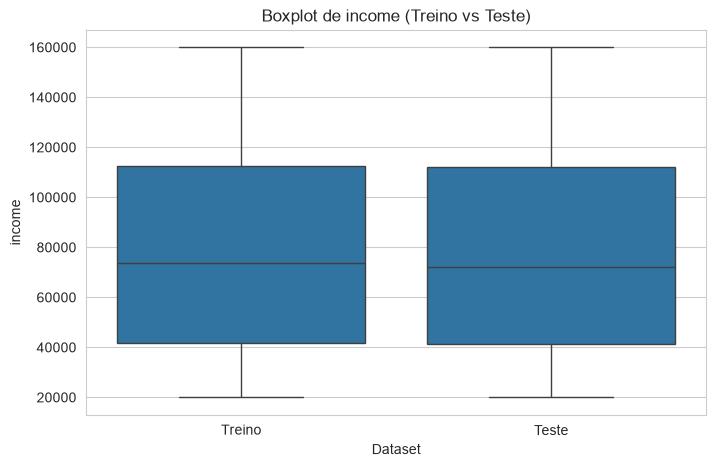

In [85]:
# Comparando coluna 'income'
comparar_boxplot("income")

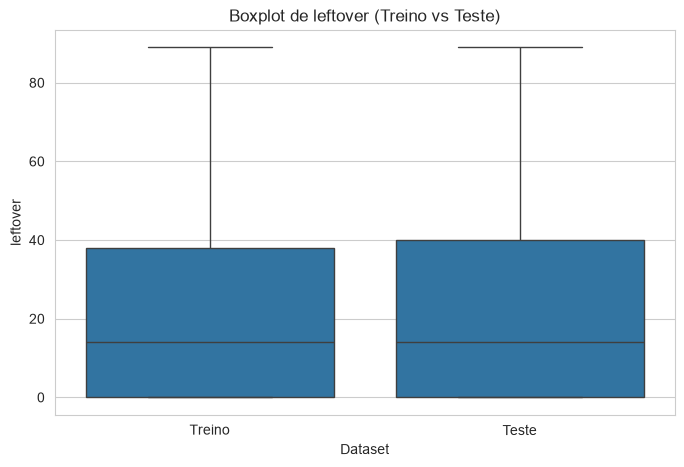

In [86]:
# Comparando coluna 'leftover'
comparar_boxplot("leftover")

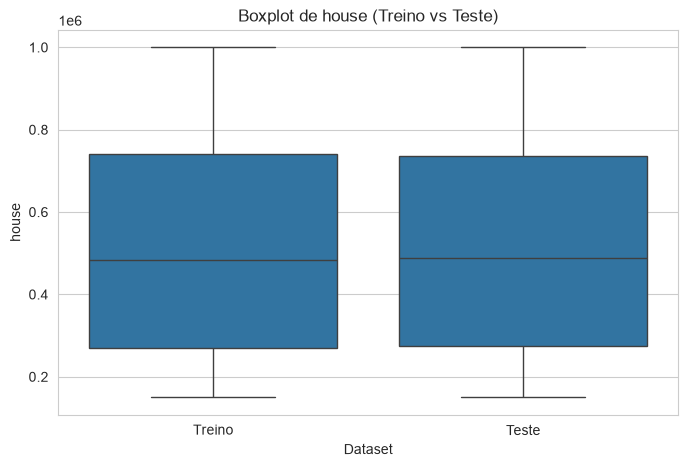

In [87]:
# Comparando coluna 'house'
comparar_boxplot("house")

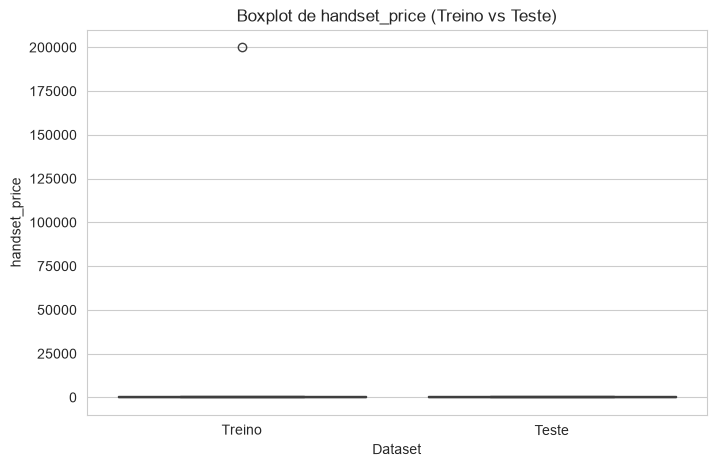

In [88]:
# Comparando coluna 'handset_price'
comparar_boxplot("handset_price")

In [89]:
print(retention_train["handset_price"].describe())

count      9854.000000
mean        402.774102
std        2021.852934
min           0.000000
25%         217.000000
50%         321.000000
75%         513.000000
max      200000.000000
Name: handset_price, dtype: float64


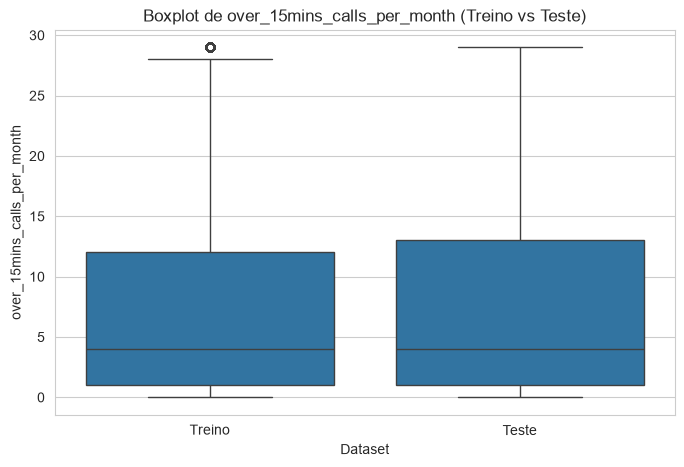

In [90]:
# Comparando coluna 'over_15mins_calls_per_month'
comparar_boxplot("over_15mins_calls_per_month")

In [91]:
print(retention_train["over_15mins_calls_per_month"].describe())

count    9854.000000
mean        7.196976
std         8.598423
min         0.000000
25%         1.000000
50%         4.000000
75%        12.000000
max        29.000000
Name: over_15mins_calls_per_month, dtype: float64


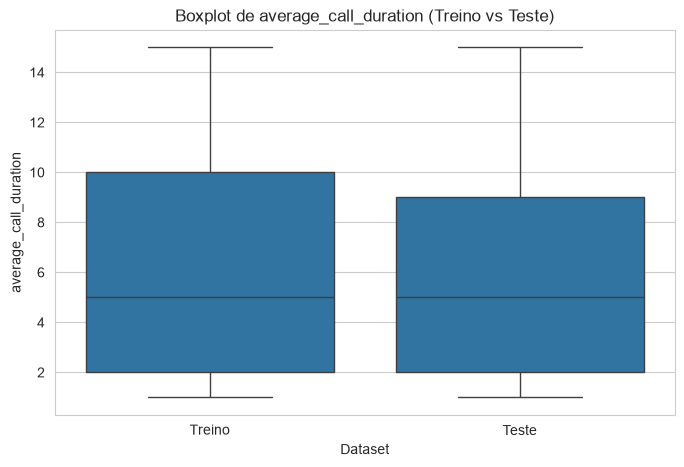

In [92]:
# Comparando coluna 'average_call_duration'
comparar_boxplot("average_call_duration")

In [93]:
# Fazendo um backup antes de alterar o dataset de TREINO
retention_train_backup = retention_train.copy()

In [94]:
retention_train_backup

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,109483,0,725532,767.0,1,2,avg,little,actively_looking_into_it,0,3.0,2.0,5.0
1,1,97561,63,220015,252.0,0,1,very_unsat,very_high,considering,0,1.0,5.0,4.0
2,0,65489,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0
3,0,155377,8,471591,539.0,0,5,very_unsat,very_little,no,0,1.0,1.0,2.0
4,0,84707,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0
9852,0,107395,12,680632,519.0,4,4,very_unsat,little,considering,1,1.0,2.0,4.0
9853,0,42242,47,779579,171.0,0,2,very_unsat,very_little,perhaps,1,1.0,1.0,3.0
9854,0,36363,61,226787,199.0,1,1,unsat,high,no,1,2.0,4.0,2.0


In [95]:
# Escolha as colunas que deseja verificar
colunas = ['handset_price']

# Criar coluna de flag de outlier
retention_train["is_outlier"] = False  # inicializa

In [96]:
for col in colunas:
    Q1 = retention_train[col].quantile(0.25)
    Q3 = retention_train[col].quantile(0.75)
    IQR = Q3 - Q1
    li = Q1 - 1.5 * IQR
    ls = Q3 + 1.5 * IQR
    retention_train["is_outlier"] |= (retention_train[col] < li) | (retention_train[col] > ls)

In [97]:
print("DataFrame com flag de outlier:")
retention_train

DataFrame com flag de outlier:


,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num,is_outlier
0,0,109483,0,725532,767.0,1,2,avg,little,actively_looking_into_it,0,3.0,2.0,5.0,False
1,1,97561,63,220015,252.0,0,1,very_unsat,very_high,considering,0,1.0,5.0,4.0,False
2,0,65489,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0,False
3,0,155377,8,471591,539.0,0,5,very_unsat,very_little,no,0,1.0,1.0,2.0,False
4,0,84707,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0,False
9852,0,107395,12,680632,519.0,4,4,very_unsat,little,considering,1,1.0,2.0,4.0,False
9853,0,42242,47,779579,171.0,0,2,very_unsat,very_little,perhaps,1,1.0,1.0,3.0,False
9854,0,36363,61,226787,199.0,1,1,unsat,high,no,1,2.0,4.0,2.0,False


In [98]:
retention_train[retention_train["is_outlier"]]

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num,is_outlier
126,0,20309,87,883556,200000.0,1,1,very_unsat,high,considering,0,1.0,4.0,4.0,True


In [99]:
# Excluir as linhas com outliers
retention_train = retention_train[~retention_train["is_outlier"]].copy()

In [100]:
print("\nDataFrame sem outliers:")
retention_train


DataFrame sem outliers:


,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num,is_outlier
0,0,109483,0,725532,767.0,1,2,avg,little,actively_looking_into_it,0,3.0,2.0,5.0,False
1,1,97561,63,220015,252.0,0,1,very_unsat,very_high,considering,0,1.0,5.0,4.0,False
2,0,65489,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0,False
3,0,155377,8,471591,539.0,0,5,very_unsat,very_little,no,0,1.0,1.0,2.0,False
4,0,84707,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0,False
9852,0,107395,12,680632,519.0,4,4,very_unsat,little,considering,1,1.0,2.0,4.0,False
9853,0,42242,47,779579,171.0,0,2,very_unsat,very_little,perhaps,1,1.0,1.0,3.0,False
9854,0,36363,61,226787,199.0,1,1,unsat,high,no,1,2.0,4.0,2.0,False


-------
## (7) Padronizando as escalas (Feature Scaling) nos conjuntos de dados
-------


In [101]:
retention_train

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num,is_outlier
0,0,109483,0,725532,767.0,1,2,avg,little,actively_looking_into_it,0,3.0,2.0,5.0,False
1,1,97561,63,220015,252.0,0,1,very_unsat,very_high,considering,0,1.0,5.0,4.0,False
2,0,65489,22,528782,260.0,4,4,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0,False
3,0,155377,8,471591,539.0,0,5,very_unsat,very_little,no,0,1.0,1.0,2.0,False
4,0,84707,0,239303,381.0,20,15,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,44872,0,453557,240.0,1,15,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0,False
9852,0,107395,12,680632,519.0,4,4,very_unsat,little,considering,1,1.0,2.0,4.0,False
9853,0,42242,47,779579,171.0,0,2,very_unsat,very_little,perhaps,1,1.0,1.0,3.0,False
9854,0,36363,61,226787,199.0,1,1,unsat,high,no,1,2.0,4.0,2.0,False


In [102]:
retention_test

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,133728,48,632969,626,3,2,unsat,high,no,0,2,4,2
1,1,50939,13,587207,336,3,5,avg,little,considering,0,3,2,4
2,1,36940,0,979303,236,10,8,very_sat,very_high,considering,0,5,5,4
3,0,159902,20,213299,516,1,4,very_sat,high,actively_looking_into_it,0,5,4,5
4,1,52308,50,187864,394,27,2,very_unsat,little,considering,0,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4227,0,150781,0,438498,889,4,15,very_unsat,little,considering,1,1,2,4
4228,1,115273,6,478182,816,21,5,very_unsat,very_little,no,1,1,1,2
4229,1,27751,67,380831,158,0,2,unsat,very_high,actively_looking_into_it,1,2,5,5
4230,0,20999,80,335638,237,1,2,unsat,little,actively_looking_into_it,1,2,2,5


In [103]:
retention_train.dtypes

college                             int64
income                              int64
leftover                            int64
house                               int64
handset_price                     float64
over_15mins_calls_per_month         int64
average_call_duration               int64
reported_satisfaction                 str
reported_usage_level                  str
considering_change_of_plan            str
leave                               int64
reported_satisfaction_num         float64
reported_usage_level_num          float64
considering_change_of_plan_num    float64
is_outlier                           bool
dtype: object

In [104]:
scaler = StandardScaler()

In [105]:
features = ['income', 'leftover', 'house', 'handset_price', 'over_15mins_calls_per_month', 'average_call_duration']

In [107]:
retention_train

In [108]:
scaler.fit_transform(retention_train[features])

array([[ 0.74631371, -0.88523063,  0.81263603,  1.83011555, -0.72080288,
        -0.92325077],
       [ 0.45668941,  1.52080299, -1.14098909, -0.62125034, -0.83710634,
        -1.1519225 ],
       [-0.32244418, -0.04502841,  0.05227438, -0.58317087, -0.3718925 ,
        -0.46590732],
       ...,
       [-0.8871897 ,  0.90974684,  1.02150651, -1.00680498, -0.83710634,
        -0.92325077],
       [-1.0300098 ,  1.44442097, -1.11481796, -0.87352683, -0.72080288,
        -1.1519225 ],
       [-0.18251497, -0.88523063,  0.95253098, -0.16905664,  1.83787324,
         1.36346647]], shape=(9853, 6))

In [109]:
# ATENÇÃO: Use fit_transform no treino e apenas transform no teste!
retention_train[features] = scaler.fit_transform(retention_train[features])
retention_test[features] = scaler.transform(retention_test[features])

In [110]:
retention_train 

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num,is_outlier
0,0,0.746314,-0.885231,0.812636,1.830116,-0.720803,-0.923251,avg,little,actively_looking_into_it,0,3.0,2.0,5.0,False
1,1,0.456689,1.520803,-1.140989,-0.621250,-0.837106,-1.151922,very_unsat,very_high,considering,0,1.0,5.0,4.0,False
2,0,-0.322444,-0.045028,0.052274,-0.583171,-0.371893,-0.465907,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0,False
3,0,1.861229,-0.579703,-0.168746,0.744851,-0.837106,-0.237236,very_unsat,very_little,no,0,1.0,1.0,2.0,False
4,0,0.144424,-0.885231,-1.066449,-0.007219,1.488963,2.049482,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9851,0,-0.823298,-0.885231,-0.238441,-0.678370,-0.720803,2.049482,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0,False
9852,0,0.695589,-0.426939,0.639115,0.649652,-0.371893,-0.465907,very_unsat,little,considering,1,1.0,2.0,4.0,False
9853,0,-0.887190,0.909747,1.021507,-1.006805,-0.837106,-0.923251,very_unsat,very_little,perhaps,1,1.0,1.0,3.0,False
9854,0,-1.030010,1.444421,-1.114818,-0.873527,-0.720803,-1.151922,unsat,high,no,1,2.0,4.0,2.0,False


In [111]:
retention_test

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,1.335304,0.947938,0.454916,1.158965,-0.488196,-0.923251,unsat,high,no,0,2,4,2
1,1,-0.675911,-0.388748,0.278064,-0.221416,-0.488196,-0.237236,avg,little,considering,0,3,2,4
2,1,-1.015993,-0.885231,1.793362,-0.697409,0.325928,0.448780,very_sat,very_high,considering,0,5,5,4
3,0,1.971156,-0.121410,-1.166944,0.635372,-0.720803,-0.465907,very_sat,high,actively_looking_into_it,0,5,4,5
4,1,-0.642654,1.024320,-1.265240,0.054660,2.303087,-0.923251,very_unsat,little,considering,0,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4227,0,1.749577,-0.885231,-0.296638,2.410827,-0.371893,2.049482,very_unsat,little,considering,1,1,2,4
4228,1,0.886972,-0.656085,-0.143275,2.063352,1.605266,-0.237236,very_unsat,very_little,no,1,1,1,2
4229,1,-1.239223,1.673567,-0.519498,-1.068684,-0.837106,-0.923251,unsat,very_high,actively_looking_into_it,1,2,5,5
4230,0,-1.403252,2.170050,-0.694152,-0.692649,-0.720803,-0.923251,unsat,little,actively_looking_into_it,1,2,2,5


In [112]:
# Fazendo uma cópia com todas as colunas do TREINO
retention_train_full = retention_train.copy()

In [113]:
retention_train.columns

Index(['college', 'income', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave', 'reported_satisfaction_num',
       'reported_usage_level_num', 'considering_change_of_plan_num',
       'is_outlier'],
      dtype='str')

In [114]:
retention_train = retention_train.drop(
    columns=[
        "reported_satisfaction",
        "reported_usage_level",
        "considering_change_of_plan",
        "is_outlier"
    ]
)

In [115]:
retention_train

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,0.746314,-0.885231,0.812636,1.830116,-0.720803,-0.923251,0,3.0,2.0,5.0
1,1,0.456689,1.520803,-1.140989,-0.621250,-0.837106,-1.151922,0,1.0,5.0,4.0
2,0,-0.322444,-0.045028,0.052274,-0.583171,-0.371893,-0.465907,0,5.0,5.0,5.0
3,0,1.861229,-0.579703,-0.168746,0.744851,-0.837106,-0.237236,0,1.0,1.0,2.0
4,0,0.144424,-0.885231,-1.066449,-0.007219,1.488963,2.049482,0,1.0,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...
9851,0,-0.823298,-0.885231,-0.238441,-0.678370,-0.720803,2.049482,1,5.0,NaN,5.0
9852,0,0.695589,-0.426939,0.639115,0.649652,-0.371893,-0.465907,1,1.0,2.0,4.0
9853,0,-0.887190,0.909747,1.021507,-1.006805,-0.837106,-0.923251,1,1.0,1.0,3.0
9854,0,-1.030010,1.444421,-1.114818,-0.873527,-0.720803,-1.151922,1,2.0,4.0,2.0


In [116]:
# Renomeando apenas algumas colunas
retention_train = retention_train.rename(columns={
    "reported_satisfaction_num": "reported_satisfaction",
    "reported_usage_level_num": "reported_usage_level",
    "considering_change_of_plan_num": "considering_change_of_plan"	
})

In [117]:
retention_train

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,leave,reported_satisfaction,reported_usage_level,considering_change_of_plan
0,0,0.746314,-0.885231,0.812636,1.830116,-0.720803,-0.923251,0,3.0,2.0,5.0
1,1,0.456689,1.520803,-1.140989,-0.621250,-0.837106,-1.151922,0,1.0,5.0,4.0
2,0,-0.322444,-0.045028,0.052274,-0.583171,-0.371893,-0.465907,0,5.0,5.0,5.0
3,0,1.861229,-0.579703,-0.168746,0.744851,-0.837106,-0.237236,0,1.0,1.0,2.0
4,0,0.144424,-0.885231,-1.066449,-0.007219,1.488963,2.049482,0,1.0,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...
9851,0,-0.823298,-0.885231,-0.238441,-0.678370,-0.720803,2.049482,1,5.0,NaN,5.0
9852,0,0.695589,-0.426939,0.639115,0.649652,-0.371893,-0.465907,1,1.0,2.0,4.0
9853,0,-0.887190,0.909747,1.021507,-1.006805,-0.837106,-0.923251,1,1.0,1.0,3.0
9854,0,-1.030010,1.444421,-1.114818,-0.873527,-0.720803,-1.151922,1,2.0,4.0,2.0


In [118]:
# Fazendo uma cópia com todas as colunas do TESTE
retention_test_full = retention_test.copy()

In [119]:
retention_test.columns

Index(['college', 'income', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave', 'reported_satisfaction_num',
       'reported_usage_level_num', 'considering_change_of_plan_num'],
      dtype='str')

In [120]:
retention_test

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,1.335304,0.947938,0.454916,1.158965,-0.488196,-0.923251,unsat,high,no,0,2,4,2
1,1,-0.675911,-0.388748,0.278064,-0.221416,-0.488196,-0.237236,avg,little,considering,0,3,2,4
2,1,-1.015993,-0.885231,1.793362,-0.697409,0.325928,0.448780,very_sat,very_high,considering,0,5,5,4
3,0,1.971156,-0.121410,-1.166944,0.635372,-0.720803,-0.465907,very_sat,high,actively_looking_into_it,0,5,4,5
4,1,-0.642654,1.024320,-1.265240,0.054660,2.303087,-0.923251,very_unsat,little,considering,0,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4227,0,1.749577,-0.885231,-0.296638,2.410827,-0.371893,2.049482,very_unsat,little,considering,1,1,2,4
4228,1,0.886972,-0.656085,-0.143275,2.063352,1.605266,-0.237236,very_unsat,very_little,no,1,1,1,2
4229,1,-1.239223,1.673567,-0.519498,-1.068684,-0.837106,-0.923251,unsat,very_high,actively_looking_into_it,1,2,5,5
4230,0,-1.403252,2.170050,-0.694152,-0.692649,-0.720803,-0.923251,unsat,little,actively_looking_into_it,1,2,2,5


In [121]:
retention_test = retention_test.drop(
    columns=[
        "reported_satisfaction",
        "reported_usage_level",
        "considering_change_of_plan"
    ]
)

In [122]:
retention_test

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,1.335304,0.947938,0.454916,1.158965,-0.488196,-0.923251,0,2,4,2
1,1,-0.675911,-0.388748,0.278064,-0.221416,-0.488196,-0.237236,0,3,2,4
2,1,-1.015993,-0.885231,1.793362,-0.697409,0.325928,0.448780,0,5,5,4
3,0,1.971156,-0.121410,-1.166944,0.635372,-0.720803,-0.465907,0,5,4,5
4,1,-0.642654,1.024320,-1.265240,0.054660,2.303087,-0.923251,0,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...
4227,0,1.749577,-0.885231,-0.296638,2.410827,-0.371893,2.049482,1,1,2,4
4228,1,0.886972,-0.656085,-0.143275,2.063352,1.605266,-0.237236,1,1,1,2
4229,1,-1.239223,1.673567,-0.519498,-1.068684,-0.837106,-0.923251,1,2,5,5
4230,0,-1.403252,2.170050,-0.694152,-0.692649,-0.720803,-0.923251,1,2,2,5


In [123]:
# Renomeando apenas algumas colunas
retention_test = retention_test.rename(columns={
    "reported_satisfaction_num": "reported_satisfaction",
    "reported_usage_level_num": "reported_usage_level",
    "considering_change_of_plan_num": "considering_change_of_plan"	
})

In [124]:
retention_test

,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,leave,reported_satisfaction,reported_usage_level,considering_change_of_plan
0,0,1.335304,0.947938,0.454916,1.158965,-0.488196,-0.923251,0,2,4,2
1,1,-0.675911,-0.388748,0.278064,-0.221416,-0.488196,-0.237236,0,3,2,4
2,1,-1.015993,-0.885231,1.793362,-0.697409,0.325928,0.448780,0,5,5,4
3,0,1.971156,-0.121410,-1.166944,0.635372,-0.720803,-0.465907,0,5,4,5
4,1,-0.642654,1.024320,-1.265240,0.054660,2.303087,-0.923251,0,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...
4227,0,1.749577,-0.885231,-0.296638,2.410827,-0.371893,2.049482,1,1,2,4
4228,1,0.886972,-0.656085,-0.143275,2.063352,1.605266,-0.237236,1,1,1,2
4229,1,-1.239223,1.673567,-0.519498,-1.068684,-0.837106,-0.923251,1,2,5,5
4230,0,-1.403252,2.170050,-0.694152,-0.692649,-0.720803,-0.923251,1,2,2,5


-------
## (9) Gravando os dataframes tratados com novos nomes
-------

###  (Somente VSCODE) *Gravando o dataframe de TREINO tratado*

In [125]:
# Gravando o dataframe de TREINO tratado, em formato CSV)
retention_train.to_csv('retention_train_tratado.csv')
retention_train_full.to_csv('retention_train_full_tratado.csv')

###  (Somente VSCODE) *Gravando o dataframe de TESTE tratado*

In [126]:
# Gravando o dataframe de TESTE tratado, em formato CSV)
retention_test.to_csv('retention_test_tratado.csv')
retention_test_full.to_csv('retention_test_full_tratado.csv')

# ***FIM***